## Configuração inicial

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [7]:
%matplotlib inline
from pathlib import Path
import os
raiz = Path.cwd()
if not (raiz / "Data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv").exists():
    candidata = raiz / ".." if raiz.name == "notebooks" else raiz.parent
    candidata = candidata.resolve()
    if(candidata / "Data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv").exists():
        os.chdir(candidata)

print("Diretório de trabalhos:", Path.cwd())

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

plt.rcParams.update({
    "figure.figsize": (8, 4.8),
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

COR_NO = "#4C78A8"
COR_YES = "#E45756"
COR_DESTAQUE = "#F58518"

Diretório de trabalhos: /Users/joaogabriel/Downloads/TRABALHO FINAL FACULDADE/telco_churn


## Conhecer os Dados

In [8]:
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [9]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [15]:
df.shape


(7043, 21)

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

RESUMO ESTATÍSTICO DE TODAS AS COLUNAS
MÉDIAS, MINIMAS, MAXIMAS E VALORES MAIS FREQUENTES

In [17]:
df.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [19]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [20]:
df['Churn'].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

## Analise da etapa 1

-> Quantos cliente existem? 
    Existem 7043 clientes(linhas) no conjunto de dados.

-> Quantas variáveis existem?
    Existem 21 váriaveis. Entre elas estão o identificador do cliente e a variável-alvo(churn). As demais 19 colunas são candidatas a variáveis preditivas.

-> Quais váriaveis são numéricas? 
    Pelo tipo armazenado no arquivo:
        -> SeniorCitizen (int64) - indicador binário 0/1 (conceitualmente categórica)
        -> tenure (int64) - tempo de permanência, em meses;
        -> MonthlyCharges(float64) - valor cobrado mensalmente

A variável TotalCharges aparece como texto, embora represente um valor monetário. Ela precisará ser convertida na Etapa 3.

-> Quais São categóricas?
    gender, Partner, Dependents, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymetMethod e Churn.

-> Existem valores ausentes ou incosistentes?
    O df.info() e o isnull() inicial não apontam valores NaN. Contudo, isso não significa que os dados estejam integros. TotalCharges está como testo e contém 11 registros em branco, todos com tenure = 0.


-> Como está ditribuído o churn?
    CHURN | FREQUENCIA | PROPORÇAO
    No      5.174           73,46%
    Yes     1.869           26,54%

    A classe positiva é minoria. Um modelo que previsse sempre "Não sai" acertaria cerca de 73% dos casos e, ainda assim, falharia em identificar justamente os clientes que cancelam. Nas etapas de modelagem, precisamos olhar além dos casos - em especial recall da clase Churn e F1-secore

## Análise explorátória
Foram escolhidas seis análises ligadas à hipótese do projeto: contrato, tempo de permanência, valor mensal, serviço de internet, suporte técnico e forma de pagamento.

Contagens:
Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48

Taxas de Churn por tipo de contrato(%):
Contract
Month-to-month    42.71%
One year          11.27%
Two year           2.83%
Name: Yes, dtype: str


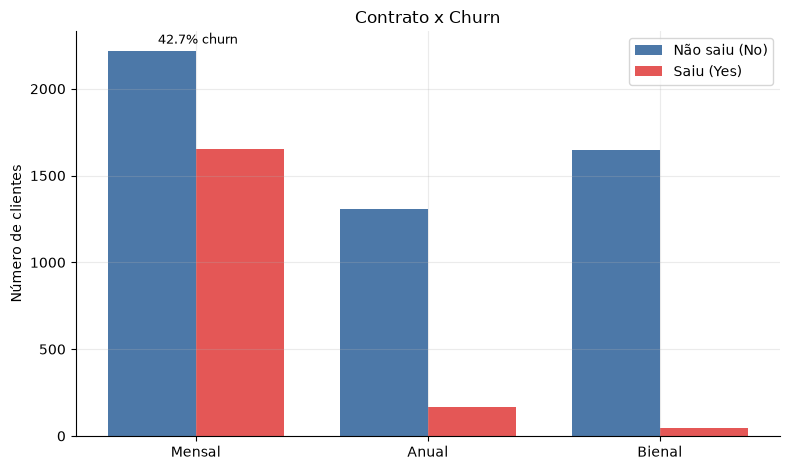

<Figure size 800x480 with 0 Axes>

<Figure size 800x480 with 0 Axes>

In [10]:
contrato_counts = pd.crosstab(df["Contract"], df["Churn"])
contrato_rate = pd.crosstab(df["Contract"], df["Churn"], normalize="index")["Yes"] * 100

ordem_contrato = ["Month-to-month", "One year", "Two year"]

contrato_counts = contrato_counts.loc[ordem_contrato]

print("Contagens:")
print(contrato_counts)
print("\nTaxas de Churn por tipo de contrato(%):")
print(contrato_rate.round(2).astype(str) + "%")

fig, ax = plt.subplots()
x = np.arange(len(ordem_contrato))
largura = 0.38
ax.bar(x - largura / 2, contrato_counts["No"],
       width=largura, label="Não saiu (No)", color=COR_NO)
ax.bar(x + largura / 2, contrato_counts["Yes"],
       width=largura, label="Saiu (Yes)", color=COR_YES)
ax.set_xticks(x)
ax.set_xticklabels(["Mensal", "Anual", "Bienal"])
ax.set_ylabel("Número de clientes")
ax.set_title("Contrato x Churn")
ax.legend()

for i, taxa in enumerate(contrato_rate):
    topo = max(contrato_counts.iloc[i]["No"],
               contrato_counts.iloc[i]["Yes"])
    ax.annotate(f"{taxa: .1f}% churn", (x[i], topo + 40), ha="center", fontsize=9)

    plt.tight_layout()
    plt.show()


